# 01 · Vetores do zero

Um vetor é só uma **lista de números** que posiciona alguma coisa num espaço. Quem já usou GPS, escolheu uma cor num editor ou mandou um arquivo para a gráfica já usou vetores.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import utils

/Users/dudanogueira/dev/weaviate/lab/claude/latinoware-2026/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2 dimensões: latitude e longitude

Cada cidade é um vetor `[latitude, longitude]`. "Perto" no mapa = vetores próximos.

In [2]:
cidades = {
    "Foz do Iguaçu": (-25.5163, -54.5854),
    "Ciudad del Este": (-25.5097, -54.6111),
    "Puerto Iguazú": (-25.5991, -54.5736),
    "Cascavel": (-24.9555, -53.4552),
    "Curitiba": (-25.4284, -49.2733),
    "Assunção": (-25.2637, -57.5759),
    "Porto Alegre": (-30.0346, -51.2177),
    "São Paulo": (-23.5505, -46.6333),
    "Buenos Aires": (-34.6037, -58.3816),
    "Manaus": (-3.1190, -60.0217),
}
nomes = list(cidades)
pontos = np.array([cidades[n] for n in nomes])


def haversine_km(a, b):
    """Distância real sobre a superfície da Terra."""
    lat1, lon1, lat2, lon2 = map(np.radians, [a[0], a[1], b[0], b[1]])
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(h))


foz = pontos[0]
euclidiana = np.linalg.norm(pontos - foz, axis=1)
for i in np.argsort(euclidiana)[1:6]:
    print(f"{nomes[i]:16} euclidiana={euclidiana[i]:6.2f}   real={haversine_km(foz, pontos[i]):7.0f} km")

Ciudad del Este  euclidiana=  0.03   real=      3 km
Puerto Iguazú    euclidiana=  0.08   real=      9 km
Cascavel         euclidiana=  1.26   real=    130 km
Assunção         euclidiana=  3.00   real=    302 km
Curitiba         euclidiana=  5.31   real=    533 km


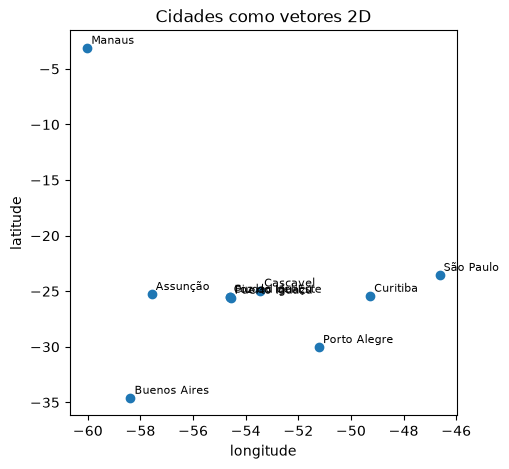

In [3]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(pontos[:, 1], pontos[:, 0])
for n, (lat, lon) in cidades.items():
    ax.annotate(n, (lon, lat), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_title("Cidades como vetores 2D")
plt.show()

A ordem dos vizinhos é a mesma com as duas métricas. A métrica muda os números, mas a ideia de "mais perto" continua: **busca por similaridade = achar os vizinhos mais próximos**.

## 3 dimensões: cores RGB

Uma cor é um vetor `[R, G, B]`. Cores parecidas ficam perto no cubo RGB.

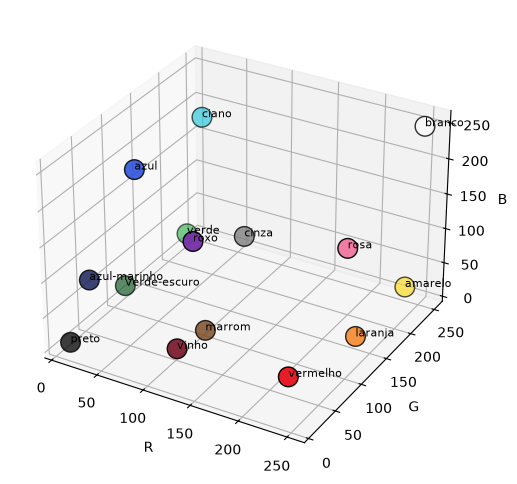

In [4]:
cores = {
    "vermelho": (230, 30, 40), "vinho": (120, 20, 40), "rosa": (240, 120, 160),
    "laranja": (245, 130, 30), "amarelo": (250, 220, 40), "verde": (40, 170, 70),
    "verde-escuro": (20, 90, 40), "azul": (40, 80, 220), "azul-marinho": (20, 30, 90),
    "ciano": (40, 200, 220), "roxo": (120, 50, 170), "marrom": (120, 70, 30),
    "branco": (250, 250, 250), "cinza": (128, 128, 128), "preto": (10, 10, 10),
}
rgb = np.array(list(cores.values()), dtype=float)

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection="3d")
ax.scatter(*rgb.T, c=rgb / 255, s=200, edgecolors="k")
for nome, (r, g, b) in cores.items():
    ax.text(r, g, b, nome, fontsize=8)
ax.set_xlabel("R"); ax.set_ylabel("G"); ax.set_zlabel("B")
plt.show()

In [5]:
def vizinhos(consulta, k=3):
    d = np.linalg.norm(rgb - np.array(consulta), axis=1)
    return [(list(cores)[i], round(d[i])) for i in np.argsort(d)[:k]]

laranja_latinoware = (240, 110, 20)
print("Mais parecidas com", laranja_latinoware, "->", vizinhos(laranja_latinoware))

Mais parecidas com (240, 110, 20) -> [('laranja', 23), ('vermelho', 83), ('amarelo', 112)]


### Distância euclidiana × cosseno

`(100, 0, 0)` e `(250, 0, 0)` são o mesmo vermelho, mais escuro e mais claro. A **distância euclidiana** diz que estão longe; o **cosseno** olha só a *direção* e diz que são iguais. Em embeddings de texto, quase sempre usamos cosseno: o que importa é *para onde* o vetor aponta.

In [6]:
def cosseno(a, b):
    a, b = np.array(a, float), np.array(b, float)
    return a @ b / (np.linalg.norm(a) * np.linalg.norm(b))

escuro, claro, azul = (100, 0, 0), (250, 0, 0), (0, 0, 250)
print("vermelho escuro x claro : euclidiana", round(np.linalg.norm(np.subtract(escuro, claro))), " cosseno", cosseno(escuro, claro))
print("vermelho claro x azul   : euclidiana", round(np.linalg.norm(np.subtract(claro, azul))), " cosseno", cosseno(claro, azul))

vermelho escuro x claro : euclidiana 150  cosseno 1.0
vermelho claro x azul   : euclidiana 354  cosseno 0.0


## 4 dimensões: CMYK

A gráfica descreve a **mesma** cor com 4 números (ciano, magenta, amarelo, preto). Dois recados:

1. O número de dimensões depende de **quem codifica**, não da coisa em si.
2. Vetores de sistemas diferentes **não são comparáveis**: não dá para medir a distância entre um RGB e um CMYK. Com embeddings é igual: as perguntas têm que ser vetorizadas **com o mesmo modelo** dos documentos.

In [7]:
def rgb_para_cmyk(r, g, b):
    r, g, b = r / 255, g / 255, b / 255
    k = 1 - max(r, g, b)
    if k == 1:
        return (0, 0, 0, 1)
    return tuple(round(x, 2) for x in ((1 - r - k) / (1 - k), (1 - g - k) / (1 - k), (1 - b - k) / (1 - k), k))

for nome in ["laranja", "azul-marinho", "cinza"]:
    print(f"{nome:13} RGB={cores[nome]}  CMYK={rgb_para_cmyk(*cores[nome])}")

laranja       RGB=(245, 130, 30)  CMYK=(0.0, 0.47, 0.88, 0.04)
azul-marinho  RGB=(20, 30, 90)  CMYK=(0.78, 0.67, 0.0, 0.65)
cinza         RGB=(128, 128, 128)  CMYK=(0.0, 0.0, 0.0, 0.5)


## 1024 dimensões: o significado de um texto

Um **modelo de embedding** faz o mesmo com texto: transforma uma frase numa coordenada num espaço de **significado**. Não dá para desenhar 1024 dimensões, mas a matemática é a mesma.

Usamos o `snowflake-arctic-embed-l-v2.0`, um modelo **open source e multilíngue** que roda aqui no notebook.

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 18373.19it/s]

forma: (7, 1024) | primeiros números: [ 0.009  0.071  0.002 -0.024 -0.039]


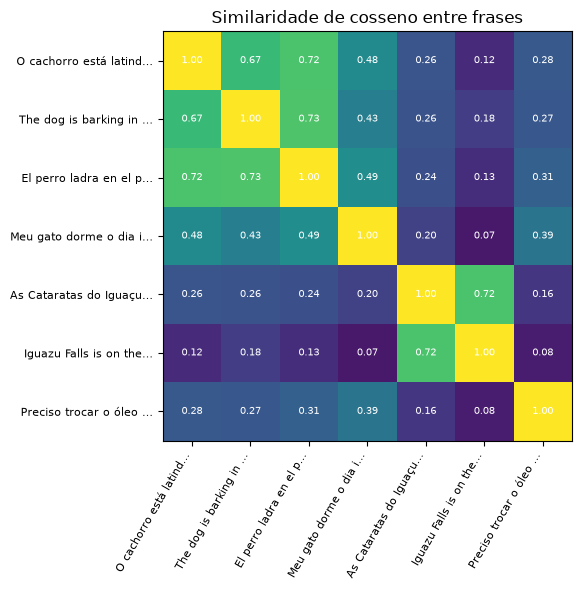

In [8]:
frases = [
    "O cachorro está latindo no quintal",
    "The dog is barking in the backyard",
    "El perro ladra en el patio",
    "Meu gato dorme o dia inteiro",
    "As Cataratas do Iguaçu ficam na fronteira",
    "Iguazu Falls is on the border of Brazil and Argentina",
    "Preciso trocar o óleo do carro",
]
model = utils.embedder()
vetores = model.encode(frases, normalize_embeddings=True)
print("forma:", vetores.shape, "| primeiros números:", vetores[0][:5].round(3))

sim = vetores @ vetores.T
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(sim, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(frases)), [f[:22] + "…" for f in frases], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(frases)), [f[:22] + "…" for f in frases], fontsize=8)
for i in range(len(frases)):
    for j in range(len(frases)):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
ax.set_title("Similaridade de cosseno entre frases")
plt.tight_layout(); plt.show()

"Cachorro", "dog" e "perro" ficam juntos, mesmo sem nenhuma palavra em comum. Isso é **busca semântica**.

## Busca por força bruta (e por que ela não escala)

25 mil passagens da Wikipedia já vetorizadas com o mesmo modelo. Perguntamos em **português** (os textos estão em inglês) e comparamos com **todos** os vetores.

In [9]:
import time

wiki = utils.load_wiki(1)
matriz = np.vstack(wiki.vector.to_numpy()).astype(np.float32)
matriz /= np.linalg.norm(matriz, axis=1, keepdims=True)
print(matriz.shape)

pergunta = "como os vulcões entram em erupção?"
q = np.array(utils.embed_query(pergunta), dtype=np.float32)

inicio = time.perf_counter()
scores = matriz @ q
top = np.argsort(-scores)[:3]
ms = (time.perf_counter() - inicio) * 1000

for i in top:
    print(f"{scores[i]:.3f}  {wiki.title[i]}: {wiki.text[i][:100]}…")
print(f"\n{len(matriz):,} vetores comparados em {ms:.1f} ms")

(25000, 1024)
0.437  Volcanism: Intrusive volcanism is when magma is forced into the rocks that make up the Earth's crust.   When it…
0.418  Intrusion: An intrusion is magma (melted rock) which cools and becomes solid under the Earth's surface.  It occ…
0.403  Carbon cycle: The main ways that carbon gets into the carbon cycle are volcanoes, and the burning of fossil fuels …

25,000 vetores comparados em 9.9 ms


Funciona! Mas o custo cresce **linearmente** com o número de vetores, e tudo precisa estar em memória:

In [10]:
bytes_por_vetor = 1024 * 4  # float32
for n in [25_000, 1_000_000, 100_000_000, 1_000_000_000]:
    print(f"{n:>13,} vetores  ~{ms * n / len(matriz):>10,.0f} ms por busca   {n * bytes_por_vetor / 1e9:>8,.1f} GB de RAM")

       25,000 vetores  ~        10 ms por busca        0.1 GB de RAM
    1,000,000 vetores  ~       395 ms por busca        4.1 GB de RAM
  100,000,000 vetores  ~    39,478 ms por busca      409.6 GB de RAM
1,000,000,000 vetores  ~   394,782 ms por busca    4,096.0 GB de RAM


E ainda faltam: persistência, filtros ("só documentos do tenant X, depois de 2024"), atualização e deleção, réplicas, backups, controle de acesso…

É para isso que existe um **banco de dados vetorial**. ➡️ `02_primeiros_passos_weaviate.ipynb`